# 102 Laser grid pixel locations, and the box wall moving (plastic, gastro, cardboard)

Find the pixel centers of the 100 main laser spots (the bright 10x10 grid) in `assets/{box}_laser_view.jpg`, photos from roughly each box's camera angle.

Method (deliberately simple, same for every box):
1. **Spot response** = grayscale blurred at σ=2 minus blurred at σ=15 (difference of Gaussians: keeps small bright dots, removes the green glow).
2. **Local maxima** in a 25 px window → keep the 130 strongest as candidates.
3. **Drop non-grid candidates** using the lattice spacing (median nearest-neighbour distance):
   - *interstitial*: a few dimmer in-between dots are just as saturated as grid spots (cores are 255). A grid spot's nearest bright neighbours are ~1 spacing away; an in-between dot has ~4 diagonal neighbours at ~0.7 spacing → drop candidates with ≥3 neighbours closer than 0.8·spacing.
   - *isolated*: stray highlights (speaker, side spots) have <2 candidate neighbours within 1.3·spacing → drop.
4. Keep the **top 100**, sort into 10 rows by y and then each row by x → `grid[row, col] = (x, y)` (row 0 = top, col 0 = left, image orientation).

Sections 4-6 then use those pixel locations to animate one vibration mode per box **on the photo of the box's side**: stretch and in-out, each its own video, at three zooms.

# 1 Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from scipy import ndimage as ndi
from scipy.spatial.distance import cdist

BOXES = ['plastic', 'gastro', 'cardboard']
imgs = {b: np.asarray(Image.open(f'../assets/{b}_laser_view.jpg').convert('RGB')) for b in BOXES}
{b: im.shape for b, im in imgs.items()}

{'plastic': (1006, 1600, 3),
 'gastro': (953, 1600, 3),
 'cardboard': (1088, 1599, 3)}

# 2 Detect the grid

In [2]:
def find_grid(img, n_cand=130, win=25):
    # 1-2: DoG response + local maxima, strongest first
    gray = img.astype(float).mean(-1)
    resp = ndi.gaussian_filter(gray, 2) - ndi.gaussian_filter(gray, 15)
    is_peak = (resp == ndi.maximum_filter(resp, win)) & (resp > 0)
    ys, xs = np.nonzero(is_peak)
    order = np.argsort(-resp[ys, xs])[:n_cand]
    cand = np.c_[xs[order], ys[order]].astype(float)

    # 3: drop interstitial (crowded) and isolated candidates
    D = cdist(cand, cand)
    np.fill_diagonal(D, np.inf)
    spacing = np.median(np.sort(D[:100], 1)[:, 0])
    interstitial = (D < 0.8 * spacing).sum(1) >= 3
    isolated = (D < 1.3 * spacing).sum(1) < 2
    drop = interstitial | isolated

    # 4: top 100 -> 10 rows by y, each row by x
    pts = cand[~drop][:100]
    pts = pts[np.argsort(pts[:, 1])].reshape(10, 10, 2)
    grid = np.stack([r[np.argsort(r[:, 0])] for r in pts])
    return grid, dict(spacing=spacing, interstitial=cand[interstitial], isolated=cand[isolated & ~interstitial])

grids, info = {}, {}
for b in BOXES:
    grids[b], info[b] = find_grid(imgs[b])
    g = grids[b]
    # sanity: within-row y spread and within-col x spread should be small (only perspective tilt)
    print(f"{b:9s} spacing {info[b]['spacing']:.1f}px | dropped {len(info[b]['interstitial'])} interstitial, "
          f"{len(info[b]['isolated'])} isolated | max row y-spread {np.ptp(g[..., 1], 1).max():.0f}, "
          f"max col x-spread {np.ptp(g[..., 0], 0).max():.0f}")

plastic   spacing 43.0px | dropped 3 interstitial, 17 isolated | max row y-spread 11, max col x-spread 16
gastro    spacing 34.0px | dropped 1 interstitial, 12 isolated | max row y-spread 4, max col x-spread 9


cardboard spacing 40.0px | dropped 1 interstitial, 27 isolated | max row y-spread 3, max col x-spread 5


In [3]:
df = pd.DataFrame([dict(box=b, row=r, col=c, x=int(grids[b][r, c, 0]), y=int(grids[b][r, c, 1]))
                   for b in BOXES for r in range(10) for c in range(10)])
df.to_csv('102_laser_grid_pixels.csv', index=False)
df.groupby('box')[['x', 'y']].agg(['min', 'max'])

x         y     
           min  max  min  max
box                          
cardboard  601  976  554  921
gastro     580  908  514  826
plastic    575  993  456  861

# 3 Overlays

In [4]:
def overlay(b):
    img, grid, inf = imgs[b], grids[b], info[b]
    fig, axes = plt.subplots(1, 2, figsize=(24, 9), gridspec_kw=dict(width_ratios=[1.6, 1]))
    for ax in axes:
        ax.imshow(img)
        ax.plot(grid[..., 0], grid[..., 1], 'w-', lw=0.6, alpha=0.6)        # columns
        ax.plot(grid[..., 0].T, grid[..., 1].T, 'w-', lw=0.6, alpha=0.6)    # rows
        ax.scatter(grid[..., 0], grid[..., 1], s=90, facecolors='none', edgecolors='red', lw=1.5)
        if len(inf['interstitial']): ax.scatter(*inf['interstitial'].T, s=90, marker='x', c='cyan', label='dropped: interstitial')
        if len(inf['isolated']): ax.scatter(*inf['isolated'].T, s=90, marker='x', c='magenta', label='dropped: isolated')
        ax.axis('off')
    axes[0].set_title(f'{b}: full image')
    pad = 40
    axes[1].set_xlim(grid[..., 0].min() - pad, grid[..., 0].max() + pad)
    axes[1].set_ylim(grid[..., 1].max() + pad, grid[..., 1].min() - pad)
    for r in range(10):
        for c in range(10):
            axes[1].text(grid[r, c, 0] + 6, grid[r, c, 1] - 6, f'{r},{c}', color='yellow', fontsize=7)
    axes[1].set_title(f'{b}: zoom, (row, col) labels')
    axes[0].legend(loc='lower right')
    plt.tight_layout()
    plt.show()

## 3.1 Plastic

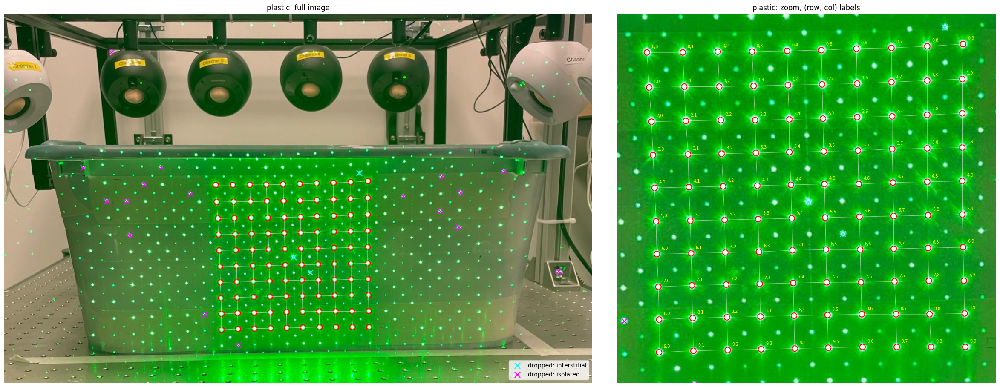

In [5]:
overlay('plastic')

## 3.2 Gastro

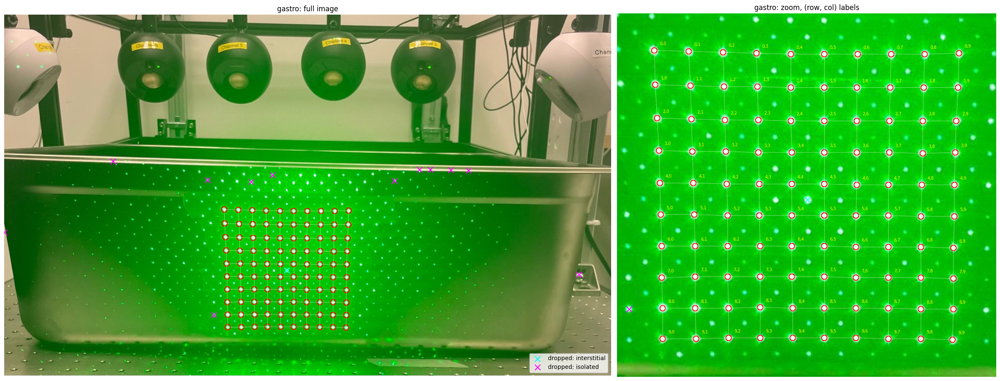

In [6]:
overlay('gastro')

## 3.3 Cardboard

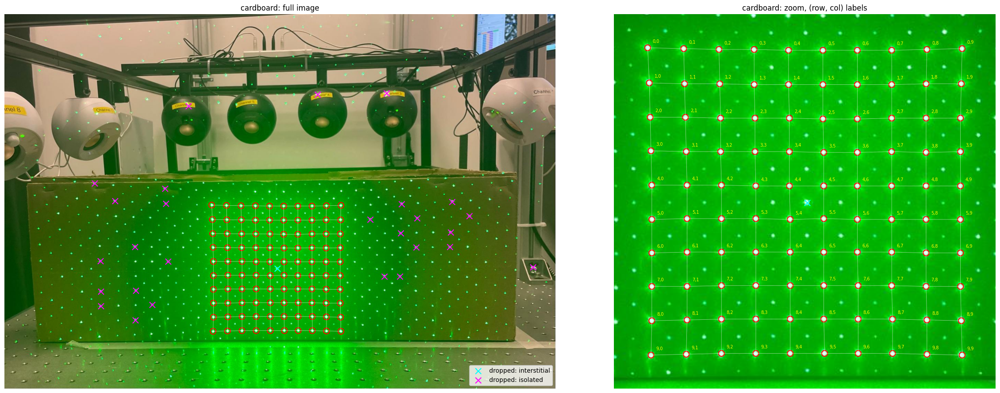

In [7]:
overlay('cardboard')

# 4 Box modes on the side photo

One mode per box: the strongest peak of that box's first **empty-box** sample (the wall's own vibration). Only its vibration data is used (viz2's `data.mode`, `data.surface`); every image is the side photo.

- **stretch**: the photo and a cell mesh (one cell per laser, centred on it) warped by the measured speckle shifts (U, V). Those are the wall's local *slope*, drawn as if it were sideways motion. This is the raw measurement.
- **in-out**: the height field Z (whose slopes are U, V): the wall moving toward and away from you, seen head-on from the camera at full photo resolution. The photo keeps its own colors: each pixel is lit by its tilt (light from the upper left) and pushed out from the photo centre by perspective. This is the physical motion. The sign of "toward" is not verified.

**Geometry.** A homography (col, row) → px, fit to the 100 spots, gives every pixel a fractional (col, row) for interpolating the mode (cubic). The motion is 1 on the grid's cells and falls smoothly to 0 at the box wall's outline (four corners picked by hand), and is 0 outside it. **Past the grid it is extrapolated.** A zoom is just a crop of these full-image fields: `grid` (laser grid + 1 cell), `wall` (the box's front face), `photo` (everything).

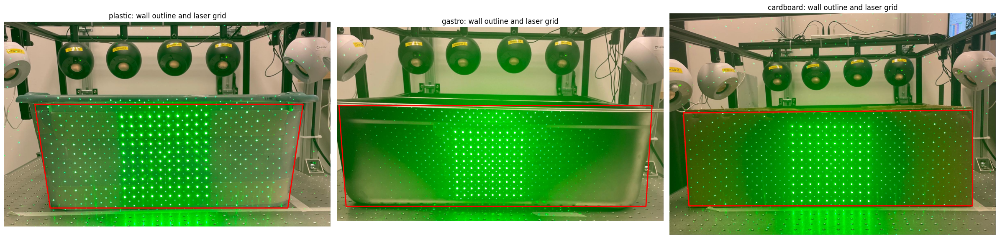

In [8]:
import sys; sys.path.insert(0, '..')
import os, subprocess, cv2, imageio_ffmpeg
from types import SimpleNamespace as NS
from scipy import ndimage as ndi
from matplotlib.path import Path as MPath
from matplotlib.patches import PathPatch
from IPython.display import Video
from viz2 import data

DATASETS = {'plastic': '2026_10_05_green_plastic_four_objs', 'gastro': '2026_09_27_gastronorm_four_objs',
            'cardboard': '2026_10_11_cardboard_four_objs'}
WALL = {'plastic':   [(150, 405), (1465, 405), (1390, 915), (225, 915)],      # front face: TL, TR, BR, BL
        'gastro':    [(10, 385), (1545, 385), (1515, 880), (45, 880)],
        'cardboard': [(68, 488), (1485, 475), (1485, 945), (95, 945)]}
ZOOMS = {'grid': 'laser grid', 'wall': 'whole box wall', 'photo': 'full photo'}
data.init('../experiments')

def box_mode(b):
    data.switch(DATASETS[b])
    sid = next(s for s, m in data.META.items() if m['empty'])
    f, freqs = data.fft(sid)
    score = np.abs(np.concatenate([f[..., 0], f[..., 1]], 0)).std(0)   # data.peaks' own score: lasers disagreeing
    fi = max(data.peaks(sid), key=lambda i: score[i])
    U, V = data.mode(sid, fi)                                          # V positive = up on screen
    return NS(sid=sid, hz=freqs[fi], U=U, V=V, Z=data.surface(U, V))

fig, axes = plt.subplots(1, 3, figsize=(24, 6))
for ax, b in zip(axes, BOXES):
    q = np.array(WALL[b] + WALL[b][:1])
    ax.imshow(imgs[b]); ax.plot(q[:, 0], q[:, 1], 'r-', lw=2); ax.plot(grids[b][..., 0], grids[b][..., 1], 'w.', ms=3)
    ax.set_title(f'{b}: wall outline and laser grid'); ax.axis('off')
plt.tight_layout()

# 5 Scene: full-image fields per box

In [9]:
tf = lambda p, M: cv2.perspectiveTransform(np.asarray(p, np.float32).reshape(1, -1, 2), M)[0]
smoothstep = lambda u: u * u * (3 - 2 * u)

def scene(b):
    m, img, g = box_mode(b), imgs[b].astype(np.float32) / 255, grids[b]
    (h, w), (R, C) = img.shape[:2], g.shape[:2]
    H = cv2.findHomography(np.stack(np.meshgrid(np.arange(C), np.arange(R)), -1).reshape(-1, 2).astype(np.float32),
                           g.reshape(-1, 2).astype(np.float32))[0]
    yy, xx = np.mgrid[:h, :w].astype(np.float32)
    cr = tf(np.stack([xx, yy], -1), np.linalg.inv(H)).reshape(h, w, 2)
    mask = lambda p: cv2.fillPoly(np.zeros((h, w), np.uint8), [np.int32(p)], 1)
    d_out = cv2.distanceTransform(1 - mask(tf([[-.5, -.5], [C - .5, -.5], [C - .5, R - .5], [-.5, R - .5]], H)), cv2.DIST_L2, 5)
    d_in = cv2.distanceTransform(mask(WALL[b]), cv2.DIST_L2, 5)
    fade = smoothstep(d_in / (d_in + d_out + 1e-6))                    # 1 on the grid, 0 at the wall outline
    dense = lambda F: ndi.map_coordinates(F, [cr[..., 1], cr[..., 0]], order=3, mode='nearest') * fade
    cell = np.linalg.norm(g[0, -1] - g[0, 0]) / (C - 1)
    # mesh: cell boundaries on half-integers, continued over the whole wall
    wc = tf(WALL[b], np.linalg.inv(H))
    (c0, r0), (c1, r1) = np.floor(wc.min(0)) - .5, np.ceil(wc.max(0)) + .5
    lines = [np.c_[np.full(99, c), np.linspace(r0, r1, 99)] for c in np.arange(c0, c1 + 1e-6)] + \
            [np.c_[np.linspace(c0, c1, 99), np.full(99, r)] for r in np.arange(r0, r1 + 1e-6)]
    gb = tf([[-1, -1], [C, -1], [C, R], [-1, R]], H)
    wb = np.array(WALL[b])
    Z = dense(m.Z)
    box = lambda p, pad: (*np.maximum(np.int32(p.min(0)) - pad, 0), *np.minimum(np.int32(p.max(0)) + pad, [w, h]))
    return NS(b=b, m=m, img=img, U=dense(m.U), V=dense(m.V), Z=Z, gy=np.gradient(Z, axis=0), gx=np.gradient(Z, axis=1), c=(w / 2, h / 2), f=float(w),
              dg=0.5 * cell / np.hypot(m.U, m.V).max(),     # stretch: biggest shift = half a cell
              zg=1.5 * cell / np.abs(m.Z).max(),            # in-out: biggest depth = 1.5 cells (px)
              lines=[tf(L, H) for L in lines],
              views={'grid': box(gb, 0), 'wall': box(wb, 25), 'photo': (0, 0, w, h)})

S = {b: scene(b) for b in BOXES}
for s in S.values(): print(f'{s.b:9s} {s.m.sid} @ {s.m.hz:.0f} Hz', s.views)

plastic   001464-1 @ 214 Hz {'grid': (np.int32(530), np.int32(411), np.int64(1036), np.int64(901)), 'wall': (np.int32(125), np.int32(380), np.int64(1490), np.int64(940)), 'photo': (0, 0, 1600, 1006)}
gastro    000005 @ 185 Hz {'grid': (np.int32(543), np.int32(479), np.int64(943), np.int64(856)), 'wall': (np.int32(0), np.int32(360), np.int64(1570), np.int64(905)), 'photo': (0, 0, 1600, 953)}
cardboard 002919-1 @ 176 Hz {'grid': (np.int32(561), np.int32(514), np.int64(1015), np.int64(959)), 'wall': (np.int32(43), np.int32(450), np.int64(1510), np.int64(970)), 'photo': (0, 0, 1599, 1088)}


# 6 Renderers

In [10]:
def stretch(ax, s, view, t):
    x0, y0, x1, y1 = view
    dx, dy = t * s.dg * s.U[y0:y1, x0:x1], -t * s.dg * s.V[y0:y1, x0:x1]        # V up -> screen y down
    yy, xx = np.mgrid[:y1 - y0, :x1 - x0].astype(np.float32)
    im = cv2.remap(s.img[y0:y1, x0:x1], xx - dx.astype(np.float32), yy - dy.astype(np.float32), cv2.INTER_LINEAR,
                   borderMode=cv2.BORDER_REFLECT)
    ax.imshow(im, extent=(x0 - .5, x1 - .5, y1 - .5, y0 - .5))                  # full-image px, so no offsets below
    clip = ax.add_patch(PathPatch(MPath(np.array(WALL[s.b], float)), fc='none', ec='none'))
    for L in s.lines:
        at = [L[:, 1], L[:, 0]]
        p = L + t * s.dg * np.c_[ndi.map_coordinates(s.U, at, order=1), -ndi.map_coordinates(s.V, at, order=1)]
        ax.plot(p[:, 0], p[:, 1], color='white', lw=0.6, alpha=0.75, clip_path=clip)
    ax.set(xlim=(x0 - .5, x1 - .5), ylim=(y1 - .5, y0 - .5)); ax.axis('off')

LIGHT = np.array([-1.0, -1.0, 1.2]) / np.linalg.norm([-1.0, -1.0, 1.2])     # upper left, in front of the wall

def in_out(ax, s, view, t):
    # the camera's own head-on view, at full photo resolution: depth d (px, + = toward you) lights each pixel by its
    # tilt and pushes it out from the photo centre by perspective (focal length = photo width)
    x0, y0, x1, y1 = view
    d, gx, gy = (t * s.zg * F[y0:y1, x0:x1] for F in (s.Z, s.gx, s.gy))
    n = np.stack([-gx, -gy, np.ones_like(d)], -1)                              # screen x right, y down, z to you
    shade = np.clip(n @ LIGHT / np.linalg.norm(n, axis=-1) / LIGHT[2], 0.3, 1.8)
    # the photo's own colors: shadow darkens; light lifts toward white, since a saturated green has no headroom
    # to be multiplied brighter (same rule as viz2's in-out shader)
    im, sh = s.img[y0:y1, x0:x1], shade[..., None]
    im = np.where(sh < 1, im * sh, im + (1 - im) * np.minimum(sh - 1, 1) * 0.7)
    # perspective: q = c + (p - c) * f / (f - d); inverted with d taken at q (d << f, so close enough)
    (cx, cy), f = s.c, s.f
    yy, xx = np.mgrid[y0:y1, x0:x1].astype(np.float32)
    k = ((f - d) / f).astype(np.float32)
    mx, my = (np.float32(c + (q - c) * k - o) for c, q, o in ((cx, xx, x0), (cy, yy, y0)))
    im = cv2.remap(im.astype(np.float32), mx, my, cv2.INTER_LINEAR,
                   borderMode=cv2.BORDER_REFLECT)
    ax.imshow(im, extent=(x0 - .5, x1 - .5, y1 - .5, y0 - .5))
    ax.set(xlim=(x0 - .5, x1 - .5), ylim=(y1 - .5, y0 - .5)); ax.axis('off')

KINDS = {'stretch': (stretch, 'stretch · the measured slope (U, V), drawn as sideways motion'),
         'in-out': (in_out, 'in-out · the wall moving toward and away from you, lit from the upper left')}

In [11]:
W_IN, HEAD_IN = 16, 1.5                       # figure width, header height (inches)
TITLE = dict(fontsize=13, color='#444', loc='left', pad=6)

def figure(s, zoom, dpi):
    x0, y0, x1, y1 = s.views[zoom]
    return plt.figure(figsize=(W_IN, W_IN * 0.98 * (y1 - y0) / (x1 - x0) + HEAD_IN), dpi=dpi, facecolor='white')

def draw(fig, s, zoom, kind, phase):
    t, T = np.cos(2 * np.pi * phase), 1000 / s.m.hz          # mode at cos(2 pi phase); one period in ms
    fig.clf()
    h = fig.get_figheight()
    ax = fig.add_axes([0.01, 0.005, 0.98, 1 - HEAD_IN / h - 0.005])
    render, title = KINDS[kind]
    render(ax, s, s.views[zoom], t); ax.set_title(title, **TITLE)
    fig.text(0.01, 1 - 0.15 / h, f'{s.b} at {s.m.hz:.0f} Hz   t = {phase * T:.2f} ms', fontsize=21, weight='bold',
             color='#222', va='top', family='monospace')
    fig.text(0.01, 1 - 0.72 / h, f'{ZOOMS[zoom]} · empty box, sample {s.m.sid} · motion exaggerated · '
             'extrapolated past the laser grid' + (' · sign of toward unverified' if kind == 'in-out' else ''),
             fontsize=12, color='#666', va='top')
    ax = fig.add_axes([0.62, 1 - 0.75 / h, 0.36, 0.5 / h])            # time slider over one period
    ax.plot([0, T], [0, 0], color='#ddd', lw=6, solid_capstyle='round')
    ax.plot([0, phase * T], [0, 0], color='#4a7bd0', lw=6, solid_capstyle='round')
    ax.plot([phase * T], [0], 'o', ms=13, color='white', mec='#4a7bd0', mew=2.5)
    for x, lab in [(0, '0'), (T / 2, f'{T / 2:.2f}'), (T, f'{T:.2f} ms')]:
        ax.text(x, -1.6, lab, ha='center', va='top', fontsize=10, color='#888')
    ax.set(xlim=(-0.03 * T, 1.03 * T), ylim=(-3, 1)); ax.axis('off')

def animate(s, zoom, kind, n=48, fps=24, dpi=150, gif_w=1600):
    # one period = n frames, so the mp4 and gif both loop seamlessly
    fig, path, wr = figure(s, zoom, dpi), f'102_modes/{s.b}_{zoom}_{kind}', None
    for j in range(n):
        draw(fig, s, zoom, kind, j / n); fig.canvas.draw()
        f = np.asarray(fig.canvas.buffer_rgba())[..., :3]
        f = np.ascontiguousarray(f[: f.shape[0] // 2 * 2, : f.shape[1] // 2 * 2])     # yuv420p: even sizes
        if wr is None:
            wr = imageio_ffmpeg.write_frames(path + '.mp4', f.shape[1::-1], fps=fps, codec='libx264',
                                             pix_fmt_out='yuv420p', quality=9, macro_block_size=2); wr.send(None)
        wr.send(f)
    wr.close(); plt.close(fig)
    vf = f'scale={gif_w}:-1:flags=lanczos,split[a][b];[a]palettegen=stats_mode=diff[p];[b][p]paletteuse=dither=sierra2_4a'
    subprocess.run([imageio_ffmpeg.get_ffmpeg_exe(), '-loglevel', 'error', '-y', '-i', path + '.mp4', '-vf', vf,
                    '-loop', '0', path + '.gif'], check=True)
    return path + '.mp4'

def show(b):
    # embedded VP9 previews: a Video(path) is only a link the notebook can't follow, and VS Code can't decode H.264
    for zoom in ZOOMS:
        for kind in KINDS:
            mp4 = animate(S[b], zoom, kind); webm = mp4.replace('.mp4', '.webm')
            subprocess.run([imageio_ffmpeg.get_ffmpeg_exe(), '-loglevel', 'error', '-y', '-i', mp4, '-vf', 'scale=1200:-2',
                            '-c:v', 'libvpx-vp9', '-b:v', '0', '-crf', '36', '-an', webm], check=True)
            display(Video(webm, embed=True, mimetype='video/webm', width=1200, html_attributes='loop autoplay muted controls'))
            os.remove(webm)

os.makedirs('102_modes', exist_ok=True)

# 7 Each box: grid, wall, photo

Saved to `102_modes/{box}_{zoom}_{stretch,in-out}.mp4` (H.264, 150 dpi) and `.gif` (1600 px wide); each is exactly one period, so both loop seamlessly.

## 7.1 Plastic

In [12]:
show('plastic')

## 7.2 Gastro

In [13]:
show('gastro')

## 7.3 Cardboard

In [14]:
show('cardboard')